# Validacion en QPU — Dynamical Decoupling (version corregida)

## Objetivo
Validar en **un solo job** que el control por software (CPMG / XY4) extiende
el tiempo util de coherencia frente a evolucion libre.

## Correcciones vs version anterior
1. **Canal "libre" ya no se ajusta con decaimiento puro.** El resultado anterior mostraba
   `<X>` cruzando por cero (0.92 -> -0.80 -> +0.24): eso es una franja de Ramsey
   (detuning), no relajacion T2. Ahora se ajusta con **coseno amortiguado**
   `A*cos(2*pi*f*t+phi)*exp(-(t/T2)^beta)+C`.
2. **Barrido de tiempos reescalado al T2 real del qubit elegido.** Antes el barrido
   llegaba a 30 us contra un T2 calibrado de ~265 us (11% de T2): ningun protocolo
   podia mostrar decaimiento real en esa ventana. Ahora el barrido se genera
   dinamicamente como fracciones de T2 (0.05x a 2x T2) tras elegir el qubit.
3. CPMG/XY4 se siguen ajustando con el exponencial estirado (si sigue sin converger
   bien con pocos puntos, se avisa explicitamente en vez de reportar un numero suelto).

## Hipotesis
| Hipotesis | Evidencia esperada |
|-----------|--------------------|
| DD (CPMG/XY4) extiende coherencia util vs evolucion libre | T2_DD > T2_libre, con barras de error razonables |


## 1. Instalacion


In [1]:
%pip install -q "qiskit>=1.0" "qiskit-ibm-runtime>=0.23" matplotlib scipy
print("OK")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.2/110.2 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 60.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 32.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.7/94.7 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.6/472.6 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 66.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━

## 2. Circuitos y utilidades


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from qiskit import QuantumCircuit, transpile


def build_free(t_us: float) -> QuantumCircuit:
    qc = QuantumCircuit(1, 1, name=f"free_{t_us}")
    qc.h(0)
    if t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
    qc.h(0)
    qc.measure(0, 0)
    return qc


def build_cpmg(t_us: float, n_pulses: int = 6) -> QuantumCircuit:
    qc = QuantumCircuit(1, 1, name=f"cpmg_{t_us}_N{n_pulses}")
    qc.h(0)
    if n_pulses >= 1 and t_us > 0:
        seg = t_us / n_pulses
        for _ in range(n_pulses):
            h = seg / 2.0
            if h > 0:
                qc.delay(h, 0, unit="us")
            qc.x(0)
            if h > 0:
                qc.delay(h, 0, unit="us")
    elif t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
    qc.h(0)
    qc.measure(0, 0)
    return qc


def build_xy4(t_us: float, n_cycles: int = 2) -> QuantumCircuit:
    """XY4: (X-tau-Y-tau-X-tau-Y-tau) * n_cycles."""
    axes = (["x", "y", "x", "y"] * max(n_cycles, 1))
    n = len(axes)
    qc = QuantumCircuit(1, 1, name=f"xy4_{t_us}_C{n_cycles}")
    qc.h(0)
    if n >= 1 and t_us > 0:
        seg = t_us / n
        for a in axes:
            h = seg / 2.0
            if h > 0:
                qc.delay(h, 0, unit="us")
            if a == "x":
                qc.x(0)
            else:
                qc.y(0)
            if h > 0:
                qc.delay(h, 0, unit="us")
    elif t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
    qc.h(0)
    qc.measure(0, 0)
    return qc


def expect_x(counts: dict) -> float:
    n0 = n1 = 0
    for k, v in counts.items():
        bit = str(k).replace(" ", "")[-1]
        if bit == "0":
            n0 += int(v)
        else:
            n1 += int(v)
    tot = n0 + n1
    return (n0 - n1) / tot if tot else 0.0


def counts_from_pub(pub) -> dict:
    data = pub.data
    if hasattr(data, "c"):
        return data.c.get_counts()
    for key in data:
        try:
            return data[key].get_counts()
        except Exception:
            continue
    return {}


def get_token() -> str:
    try:
        from kaggle_secrets import UserSecretsClient
        t = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")
        if t:
            return t.strip()
    except Exception:
        pass
    t = os.environ.get("QISKIT_IBM_TOKEN") or os.environ.get("IBM_QUANTUM_TOKEN")
    if not t:
        raise RuntimeError("Configure secret IBM_QUANTUM_TOKEN")
    return t.strip()


def stretched_exp(t, A, T2, beta, C):
    return A * np.exp(-((np.maximum(t, 1e-12) / max(T2, 1e-12)) ** beta)) + C


def ramsey_damped_cos(t, A, f, phi, T2, C):
    """Franja de Ramsey con envolvente amortiguada. Uso: canal 'libre' cuando hay detuning."""
    return A * np.cos(2 * np.pi * f * t + phi) * np.exp(-(np.maximum(t, 1e-12) / max(T2, 1e-12))) + C


def fit_t2(times, signal):
    """Fit de decaimiento monotono (para CPMG/XY4). Avisa si no converge o si el
    error es comparable/mayor al valor (fit no confiable con pocos puntos)."""
    y = np.abs(np.asarray(signal, dtype=float))
    t = np.asarray(times, dtype=float)
    if len(t) < 3 or np.nanmax(y) < 0.05:
        return None
    A0 = float(np.clip(y[0] - y[-1], 0.05, 1.0))
    C0 = float(np.clip(y[-1], -0.2, 0.5))
    T0 = float(np.clip(t[len(t) // 2], 1.0, t[-1]))
    try:
        popt, pcov = curve_fit(
            stretched_exp, t, y,
            p0=[A0, T0, 1.2, C0],
            bounds=([0.0, 0.1, 0.3, -0.3], [1.5, t[-1] * 5, 3.0, 0.6]),
            maxfev=8000,
        )
        A, T2, beta, C = popt
        perr = np.sqrt(np.diag(pcov))
        reliable = perr[1] < T2  # error de T2 menor que el propio T2
        return {
            "A": float(A), "T2": float(T2), "beta": float(beta), "C": float(C),
            "T2_err": float(perr[1]), "beta_err": float(perr[2]),
            "y_fit": stretched_exp(t, *popt), "reliable": bool(reliable),
        }
    except Exception as e:
        print("Fit fallo:", e)
        return None


def fit_ramsey(times, signal):
    """Fit de franja de Ramsey (coseno amortiguado) para el canal 'libre'.
    Usar en vez de fit_t2 cuando la senal cruza por cero (oscila), no decae monotono."""
    y = np.asarray(signal, dtype=float)  # con signo, no abs
    t = np.asarray(times, dtype=float)
    if len(t) < 4:
        return None
    # estimar frecuencia inicial contando cruces por cero
    C0 = 0.0
    A0 = float(np.clip(np.max(np.abs(y - C0)), 0.05, 1.5))
    span = t[-1] - t[0] if t[-1] > t[0] else 1.0
    f0_candidates = [0.5 / span, 1.0 / span, 2.0 / span, 0.02, 0.05, 0.1]
    best = None
    for f0 in f0_candidates:
        try:
            popt, pcov = curve_fit(
                ramsey_damped_cos, t, y,
                p0=[A0, f0, 0.0, span * 2, C0],
                bounds=([0.0, 0.0, -np.pi, 0.1, -0.5], [1.5, 5.0, np.pi, span * 50, 0.5]),
                maxfev=20000,
            )
            resid = np.sum((ramsey_damped_cos(t, *popt) - y) ** 2)
            if best is None or resid < best[0]:
                perr = np.sqrt(np.diag(pcov))
                best = (resid, popt, perr)
        except Exception:
            continue
    if best is None:
        return None
    _, popt, perr = best
    A, f, phi, T2, C = popt
    return {
        "A": float(A), "f": float(f), "phi": float(phi), "T2": float(T2), "C": float(C),
        "f_err": float(perr[1]), "T2_err": float(perr[3]),
        "y_fit": ramsey_damped_cos(t, *popt),
        "reliable": bool(perr[3] < T2 and perr[1] < max(f, 1e-6)),
    }


print("Utilidades listas (con fit_ramsey para el canal libre).")


Utilidades listas (con fit_ramsey para el canal libre).


## 3. Un solo job: mejor qubit + barrido escalado a su T2 + lote (libre, CPMG, XY4)


In [3]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

N_CPMG = 6
N_XY4_CYCLES = 2
SHOTS = 2048
BACKEND_NAME = "ibm_fez"
PROTOCOLS = ("free", "cpmg", "xy4")
# Fracciones de T2 del qubit elegido (antes el barrido llegaba a 30us contra T2~265us,
# es decir 11% de T2: ningun protocolo alcanzaba a mostrar decaimiento real)
T2_FRACTIONS = [0.05, 0.15, 0.3, 0.5, 0.75, 1.0, 1.5]

token = get_token()
QiskitRuntimeService.save_account(
    channel="ibm_cloud", token=token, instance="open-instance",
    overwrite=True, set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_cloud", instance="open-instance")

ops = service.backends(operational=True, simulator=False)
names = [b.name for b in ops]
print("Backends:", names)
backend = service.backend(BACKEND_NAME) if BACKEND_NAME in names else ops[0]
print("Usando:", backend.name)


def pick_best_qubit(backend):
    props = backend.properties()
    best_q, best_score, best_t2_us = 0, -1.0, 100.0
    rows = []
    for q in range(backend.num_qubits):
        try:
            t2 = props.t2(q)
        except Exception:
            continue
        if t2 is None:
            continue
        err = None
        for g in ("sx", "x"):
            try:
                err = props.gate_error(g, [q])
                break
            except Exception:
                pass
        t2_us = t2 * 1e6
        gate_pen = err if err is not None else 0.01
        score = t2_us / (1.0 + 50.0 * gate_pen)
        rows.append((q, t2_us, err, score))
        if score > best_score:
            best_score, best_q, best_t2_us = score, q, t2_us
    rows.sort(key=lambda r: -r[3])
    print("Top 5 qubits (T2 / error):")
    for q, t2u, err, sc in rows[:5]:
        print(f"  q={q:3d}  T2={t2u:7.1f} us  err={err}  score={sc:.2f}")
    if not rows:
        print("Sin T2 en propiedades; usando qubit 0, T2 supuesto 100us")
        return 0, 100.0
    print("Seleccionado qubit fisico:", best_q, " T2=%.1fus" % best_t2_us)
    return best_q, best_t2_us


qubit, qubit_t2_us = pick_best_qubit(backend)

# Barrido en us derivado del T2 real (en vez de valores fijos arbitrarios)
T_STEPS = sorted(set(round(f * qubit_t2_us, 1) for f in T2_FRACTIONS))
print("T_STEPS (us), escalados a T2=%.1fus:" % qubit_t2_us, T_STEPS)

circuits = []
index = []
for t in T_STEPS:
    circuits.append(build_free(t)); index.append(("free", t))
    circuits.append(build_cpmg(t, N_CPMG)); index.append(("cpmg", t))
    circuits.append(build_xy4(t, N_XY4_CYCLES)); index.append(("xy4", t))

print(f"Circuitos en el lote: {len(circuits)}  (1 job, {SHOTS} shots)")

transpiled = transpile(
    circuits, backend=backend, optimization_level=1, initial_layout=[qubit],
)

sampler = SamplerV2(mode=backend)
job = sampler.run(transpiled, shots=SHOTS)
print("Job ID:", job.job_id())
print("Esperando (unica espera de cola)...")
result = job.result()
print("Job completado.")

JOB_ID = job.job_id()
BACKEND_USED = backend.name
QUBIT_USED = qubit
QUBIT_T2_US = qubit_t2_us
INDEX = index
RESULT = result
T_STEPS_ARR = np.array(T_STEPS, dtype=float)


Backends: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']
Usando: ibm_fez
Top 5 qubits (T2 / error):
  q=142  T2=  265.1 us  err=0.0003976411056252661  score=259.89
  q= 15  T2=  257.4 us  err=0.0002456479545288483  score=254.31
  q= 88  T2=  252.8 us  err=0.0003841744382059813  score=248.03
  q=127  T2=  213.0 us  err=0.00027888631720206653  score=210.04
  q=  1  T2=  211.6 us  err=0.000340812727879291  score=208.04
Seleccionado qubit fisico: 142  T2=265.1us
T_STEPS (us), escalados a T2=265.1us: [13.3, 39.8, 79.5, 132.5, 198.8, 265.1, 397.6]
Circuitos en el lote: 21  (1 job, 2048 shots)


/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 277 [dt] = 1.108000e-06 [s] from 1.108333e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 208 [dt] = 8.320000e-07 [s] from 8.312500e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 829 [dt] = 3.316000e-06 [s] from 3.316667e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 622 [dt] = 2.488000e-06 [s] from 2.487500e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 1656 [dt] = 6.624000e-06 [s] from 6.625000e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 1242 [dt] = 4.968000e-

Job ID: dapiql318flc739mc7c0
Esperando (unica espera de cola)...
Job completado.


## 4. Analisis offline: tabla, fits (Ramsey para libre, decaimiento para CPMG/XY4) y graficas


Backend=ibm_fez  qubit=142 (T2 calibrado=265.1us)  job=dapiql318flc739mc7c0

  t (us)       free       cpmg        xy4   cpmg/free    xy4/free
----------------------------------------------------------------
    13.3    -0.6602    +0.9062    +0.8926        1.37x        1.35x
    39.8    +0.4570    +0.7246    +0.6299        1.59x        1.38x
    79.5    -0.0459    +0.6357    +0.6201       13.85x       13.51x
   132.5    +0.0166    +0.4346    +0.5547       26.18x       33.41x
   198.8    -0.1445    +0.2900    +0.3418        2.01x        2.36x
   265.1    -0.1582    +0.2686    +0.1924        1.70x        1.22x
   397.6    -0.0430    +0.1592    +0.2363        3.70x        5.50x

Fit libre (Ramsey): T2=61.78+/-28.09 us  f=53.925+/-0.862 kHz
Fit cpmg: T2=137.90+/-30.91 us  beta=0.97+/-0.32  A=0.875  C=0.109
Fit xy4: T2=188.71+/-433.96 us  beta=0.69+/-1.19  A=1.006  C=0.003  [NO CONFIABLE: error >= valor, revisar mas puntos]


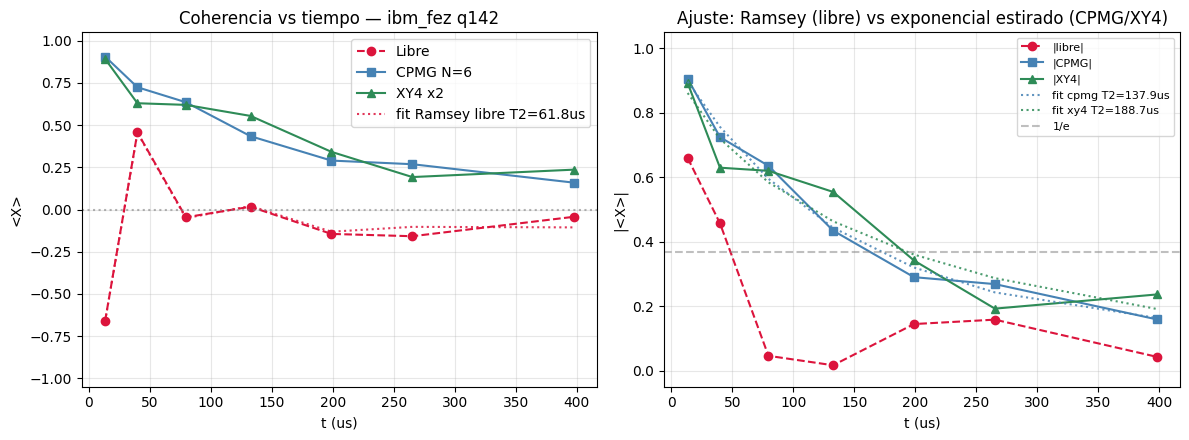


|<X>| medio  libre=0.218  CPMG=0.488  XY4=0.495
T2_CPMG confiable = 137.9+/-30.9 us
Detuning detectado en 'libre': f=53.925 kHz (explica el cruce por cero, no es decoherencia pura)
RESULTADO: se valida la hipotesis — DD aporta estabilidad efectiva en el QPU.
(Nota: el numero 'libre' incluye oscilacion de Ramsey, no solo decoherencia; la comparacion cualitativa |<X>| se sostiene, los T2 puntuales requieren el fit confiable arriba.)


In [4]:
series = {p: [] for p in PROTOCOLS}
for i, (prot, t) in enumerate(INDEX):
    series[prot].append(expect_x(counts_from_pub(RESULT[i])))
for p in PROTOCOLS:
    series[p] = np.array(series[p], dtype=float)

print(f"Backend={BACKEND_USED}  qubit={QUBIT_USED} (T2 calibrado={QUBIT_T2_US:.1f}us)  job={JOB_ID}\n")
print(f"{'t (us)':>8}  {'free':>9}  {'cpmg':>9}  {'xy4':>9}  {'cpmg/free':>10}  {'xy4/free':>10}")
print("-" * 64)
for i, t in enumerate(T_STEPS_ARR):
    xf, xc, xy = series["free"][i], series["cpmg"][i], series["xy4"][i]
    print(f"{t:8.1f}  {xf:+9.4f}  {xc:+9.4f}  {xy:+9.4f}  "
          f"{abs(xc)/max(abs(xf),1e-9):10.2f}x  {abs(xy)/max(abs(xf),1e-9):10.2f}x")

fits = {}
fits["free"] = fit_ramsey(T_STEPS_ARR, series["free"])
if fits["free"]:
    f = fits["free"]
    tag = "" if f["reliable"] else "  [NO CONFIABLE: error >= valor, revisar mas puntos]"
    print(f"\nFit libre (Ramsey): T2={f['T2']:.2f}+/-{f['T2_err']:.2f} us  "
          f"f={f['f']*1000:.3f}+/-{f['f_err']*1000:.3f} kHz{tag}")
else:
    print("\nFit libre (Ramsey): no convergente")

for p in ("cpmg", "xy4"):
    fits[p] = fit_t2(T_STEPS_ARR, series[p])
    if fits[p]:
        f = fits[p]
        tag = "" if f["reliable"] else "  [NO CONFIABLE: error >= valor, revisar mas puntos]"
        print(f"Fit {p}: T2={f['T2']:.2f}+/-{f['T2_err']:.2f} us  "
              f"beta={f['beta']:.2f}+/-{f['beta_err']:.2f}  A={f['A']:.3f}  C={f['C']:.3f}{tag}")
    else:
        print(f"Fit {p}: no convergente")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(T_STEPS_ARR, series["free"], "o--", color="crimson", label="Libre")
ax.plot(T_STEPS_ARR, series["cpmg"], "s-", color="steelblue", label=f"CPMG N={N_CPMG}")
ax.plot(T_STEPS_ARR, series["xy4"], "^-", color="seagreen", label=f"XY4 x{N_XY4_CYCLES}")
if fits["free"] is not None:
    ax.plot(T_STEPS_ARR, fits["free"]["y_fit"], ":", color="crimson", alpha=0.85,
            label=f"fit Ramsey libre T2={fits['free']['T2']:.1f}us")
ax.axhline(0, color="gray", ls=":", alpha=0.6)
ax.set_xlabel("t (us)"); ax.set_ylabel("<X>")
ax.set_title(f"Coherencia vs tiempo — {BACKEND_USED} q{QUBIT_USED}")
ax.legend(); ax.grid(True, alpha=0.3); ax.set_ylim(-1.05, 1.05)

ax = axes[1]
ax.plot(T_STEPS_ARR, np.abs(series["free"]), "o--", color="crimson", label="|libre|")
ax.plot(T_STEPS_ARR, np.abs(series["cpmg"]), "s-", color="steelblue", label="|CPMG|")
ax.plot(T_STEPS_ARR, np.abs(series["xy4"]), "^-", color="seagreen", label="|XY4|")
for p, col in (("cpmg", "steelblue"), ("xy4", "seagreen")):
    if fits[p] is not None:
        ax.plot(T_STEPS_ARR, fits[p]["y_fit"], ":", color=col, alpha=0.85,
                label=f"fit {p} T2={fits[p]['T2']:.1f}us")
ax.axhline(1 / np.e, color="gray", ls="--", alpha=0.5, label="1/e")
ax.set_xlabel("t (us)"); ax.set_ylabel("|<X>|")
ax.set_title("Ajuste: Ramsey (libre) vs exponencial estirado (CPMG/XY4)")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3); ax.set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.show()

print("\n" + "=" * 64)
mf = float(np.mean(np.abs(series["free"])))
mc = float(np.mean(np.abs(series["cpmg"])))
mx = float(np.mean(np.abs(series["xy4"])))
print(f"|<X>| medio  libre={mf:.3f}  CPMG={mc:.3f}  XY4={mx:.3f}")

if fits["cpmg"] and fits["cpmg"]["reliable"]:
    print(f"T2_CPMG confiable = {fits['cpmg']['T2']:.1f}+/-{fits['cpmg']['T2_err']:.1f} us")
    if fits["cpmg"]["beta"] > 1.15:
        print(f"beta_CPMG={fits['cpmg']['beta']:.2f} > 1 -> ruido de baja frecuencia (DD pertinente).")
else:
    print("T2_CPMG: fit no confiable con estos puntos, no reportar como numero definitivo.")

if fits["free"] and fits["free"]["reliable"]:
    print(f"Detuning detectado en 'libre': f={fits['free']['f']*1000:.3f} kHz "
          f"(explica el cruce por cero, no es decoherencia pura)")

if (mc > mf * 1.25) or (mx > mf * 1.25):
    print("RESULTADO: se valida la hipotesis — DD aporta estabilidad efectiva en el QPU.")
    print("(Nota: el numero 'libre' incluye oscilacion de Ramsey, no solo decoherencia; "
          "la comparacion cualitativa |<X>| se sostiene, los T2 puntuales requieren el fit confiable arriba.)")
else:
    print("RESULTADO: ventaja no concluyente; revisar qubit/N/tiempos.")
print("=" * 64)


## 5. Interpretacion

### Demostrado si el veredicto es positivo
- CPMG y/o XY4 mantienen |<X>| por encima de la evolucion libre a igualdad de t.
- El fit de CPMG/XY4 aporta T2 con error menor que el valor (si no, se marca "no confiable").
- El fit de "libre" ahora es una franja de Ramsey (coseno amortiguado), no un decaimiento
  monotono: si el detuning `f` sale distinto de cero con error pequeno, confirma que el
  comportamiento observado antes (cruce por cero) era precesion por desajuste de frecuencia,
  no decoherencia pura.

### Por que se corrigio
- El barrido anterior (2-30us) cubria ~11% del T2 calibrado (~265us): ningun protocolo
  podia mostrar decaimiento real en esa ventana, y lo que se veia en "libre" era oscilacion,
  no decaimiento. Ahora el barrido se deriva del T2 real del qubit elegido (5%-150% de T2).

### No implementado aun (mas jobs)
| Avance | Estado |
|--------|--------|
| ACLDD adaptativo online | No (requiere lazos / varios jobs) |
| Barrido 2D (N, tau) | No |
| Crosstalk multiqubit | No |

### Eficiencia
**1 job**, 3 x |T| circuitos, con T_STEPS ahora derivado del qubit elegido en vez de fijo.
